# Bubble Detection with SADF & GSADF in Quantitative Trading

## What is a Financial Bubble?
A **financial bubble** is a period during which an asset's price deviates dramatically above its fundamental value, driven by speculative excess and positive-feedback trading. Bubbles are characterized by a **super-exponential** (convex, parabolic) price trajectory, followed by a violent crash. Identifying these explosive regimes in real-time is one of the most valuable capabilities a quantitative trader can possess.

## Stationarity, Unit Roots, and the ADF Test
Standard time series analysis depends on **stationarity** — a property where the mean, variance, and autocorrelation structure remain constant over time. Most raw asset price series are **non-stationary**; they behave like a Random Walk:

$$P_t = P_{t-1} + \varepsilon_t, \quad \varepsilon_t \sim N(0, \sigma^2)$$

The **Augmented Dickey-Fuller (ADF) test** is the workhorse unit root test. It regresses the first difference of the series on its lagged level:

$$\Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \sum_{i=1}^{p} \delta_i \Delta y_{t-i} + \varepsilon_t$$

The key coefficient is $\gamma$:

| Value of $\gamma$ | Interpretation | Regime |
|---|---|---|
| $\gamma = 0$ | Unit root | Random Walk |
| $\gamma < 0$ | Mean-reverting | Stationary |
| **$\gamma > 0$** | **Explosive root** | **Bubble Regime** |

When $\gamma > 0$, the current price depends on the previous price with a multiplier exceeding 1. This creates the convex, parabolic curves seen in late-stage bull manias.

## Why Traditional ADF Fails for Bubbles
The standard ADF test computes $\gamma$ over the **entire** dataset. If a bubble forms and then collapses within the sample, the explosive upward phase and the subsequent crash average out. The test will fail to reject the null hypothesis of a random walk, completely missing the temporary bubble.

## Supremum ADF (SADF) — Phillips, Wu, and Yu (2011)
To detect bubbles occurring *within* a sample, the **SADF test** runs the ADF regression repeatedly over a **forward-expanding window**:

1. Fix the starting point at $t = 0$.
2. Set a minimum window size $r_0$ (e.g., 5% of the sample).
3. Calculate the ADF t-statistic for $[0, r_0]$.
4. Expand: calculate for $[0, r_0 + 1]$, then $[0, r_0 + 2]$, ..., up to $[0, T]$.

The SADF statistic is:
$$\text{SADF}(r_0) = \sup_{r \in [r_0, 1]} \text{ADF}_0^r$$

The full sequence $\{\text{ADF}_0^r\}_{r=r_0}^T$ can be tracked over time to timestamp the exact inception and collapse of a bubble.

## Generalized SADF (GSADF) — Phillips, Shi, and Yu (2015)
SADF has a weakness: if a sample contains **multiple** bubbles, the distortion from the first bubble's collapse corrupts the initial window, masking subsequent bubbles.

GSADF fixes this by also varying the **start point** $r_1$, testing every possible sub-window $[r_1, r_2]$ with $r_2 - r_1 \ge r_0$:

$$\text{GSADF}(r_0) = \sup_{\substack{r_2 \in [r_0, 1] \\ r_1 \in [0, r_2 - r_0]}} \text{ADF}_{r_1}^{r_2}$$

The associated **Backward SADF (BSADF)** sequence at each time $t$ is:
$$\text{BSADF}_t(r_0) = \sup_{r_1 \in [0, t - r_0]} \text{ADF}_{r_1}^{t}$$

This is the value we track over time — when $\text{BSADF}_t$ exceeds the **Monte Carlo simulated critical value**, the asset is in an explosive (bubble) regime.

## Phase 2: Environment Setup and Data Ingestion

We will import the necessary libraries, including `statsmodels` for OLS regression, and fetch daily data for Bitcoin (`BTC-USD`) — which famously exhibits powerful boom-and-bust cycles — and the S&P 500 (`SPY`) for comparison.

c:\Users\vansh\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


[*********************100%***********************]  2 of 2 completed


Data Shape: (3650, 2)


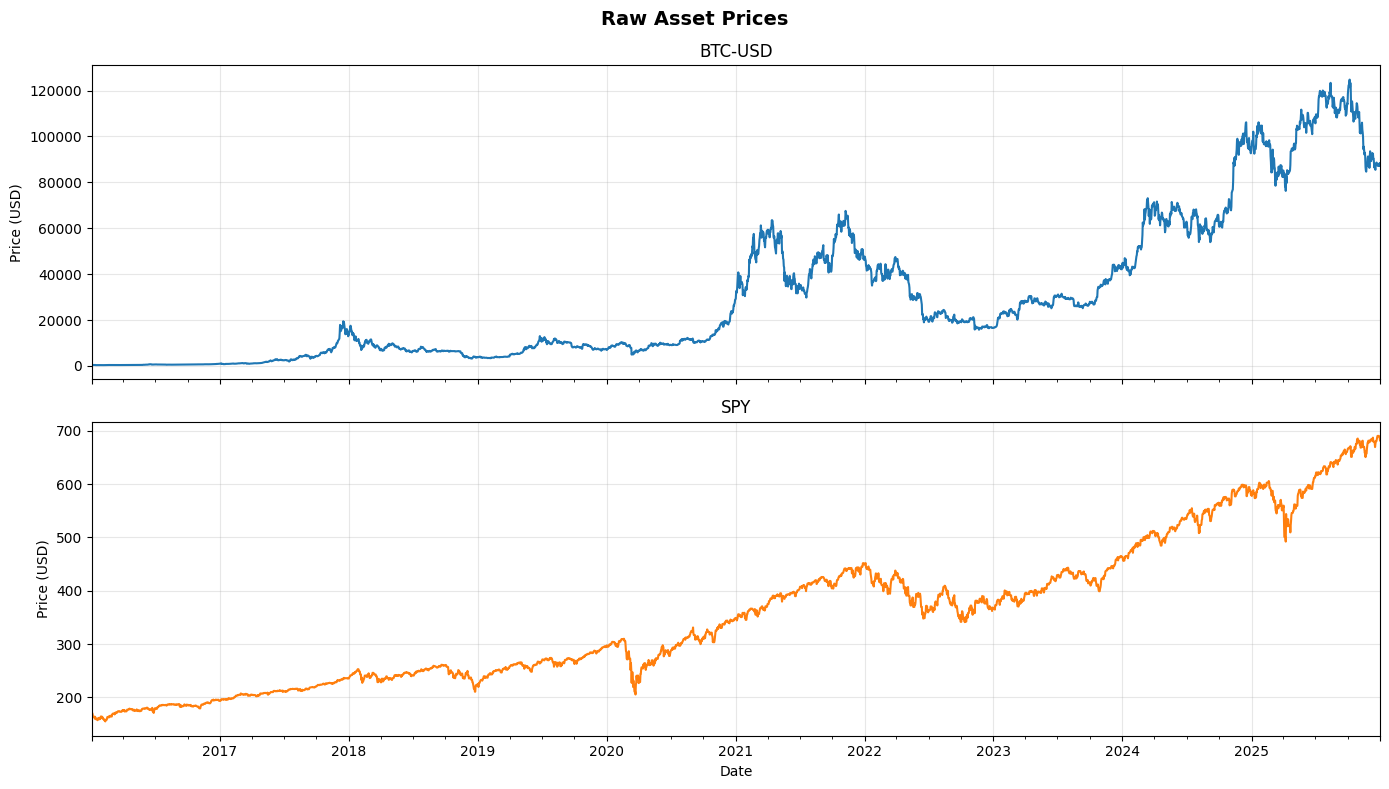

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Define assets and timeframe
tickers = ['BTC-USD', 'SPY']
start_date = '2016-01-01'
end_date = '2026-01-01'

print('Downloading data...')
raw = yf.download(tickers, start=start_date, end=end_date, interval='1d', auto_adjust=True)
close_prices = raw['Close'].ffill()
close_prices.columns.name = None
close_prices.dropna(inplace=True)

# We use the natural logarithm of prices.
# Explosive growth in nominal terms is standard compounding,
# but explosive growth in LOG terms is exponential compounding — a true bubble.
btc_log = np.log(close_prices['BTC-USD'])
spy_log = np.log(close_prices['SPY'])

print(f'Data Shape: {close_prices.shape}')

# Visualize raw prices
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
colors = ['#1f77b4', '#ff7f0e']

for ax, ticker, color in zip(axes, tickers, colors):
    close_prices[ticker].plot(ax=ax, title=ticker, color=color)
    ax.set_ylabel('Price (USD)')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
fig.suptitle('Raw Asset Prices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Phase 3: Implementing the SADF Expanding Window

### The Core OLS Loop
At each expanding step $t$, we run the simplified ADF regression (lag order $k=0$, pure AR(1) explosivity test):

$$\Delta y_t = \alpha + \gamma y_{t-1} + \varepsilon_t$$

The ADF t-statistic for $\gamma$ is:
$$t_\gamma = \frac{\hat{\gamma}}{\text{SE}(\hat{\gamma})}$$

We store this t-statistic at every step to build the **SADF sequence**.

> **Note:** A minimum window $r_0$ is required to ensure the OLS regression is well-conditioned. A common rule of thumb is 5–10% of the total sample.

In [2]:
def calculate_sadf_sequence(series, min_window=100):
    """
    Calculates the SADF (Supremum Augmented Dickey-Fuller) sequence
    using a forward-expanding window.
    
    Parameters
    ----------
    series : pd.Series
        Log price series.
    min_window : int
        Minimum initial window size (r_0).
        
    Returns
    -------
    pd.Series
        ADF t-statistic at each expanding step.
    """
    y = series.values
    n = len(y)
    sequence = np.full(n, np.nan)
    
    # Pre-compute differences and lags
    dy = np.diff(y)
    y_lag = y[:-1]
    
    print(f"Calculating SADF sequence (min_window={min_window})...")
    for t in tqdm(range(min_window, n), desc="SADF"):
        dy_window = dy[:t]
        y_lag_window = y_lag[:t]
        
        X = sm.add_constant(y_lag_window)
        try:
            results = sm.OLS(dy_window, X).fit()
            sequence[t] = results.tvalues[1]  # t-stat of gamma
        except Exception:
            sequence[t] = np.nan
            
    return pd.Series(sequence, index=series.index)

# Calculate SADF for BTC
min_window_size = int(len(btc_log) * 0.05)  # 5% of sample
print(f"Minimum window size: {min_window_size} days")
btc_sadf = calculate_sadf_sequence(btc_log, min_window=min_window_size)
print(f"\nSADF Statistic (Supremum): {np.nanmax(btc_sadf.values):.4f}")

Minimum window size: 182 days
Calculating SADF sequence (min_window=182)...


SADF: 100%|██████████| 3468/3468 [00:00<00:00, 3705.52it/s]


SADF Statistic (Supremum): 3.2069


## Phase 4: Implementing the Generalized SADF (GSADF / BSADF)

While SADF keeps the start of the window fixed at $t=0$, the **BSADF** at each point $t$ calculates the ADF statistic for **all valid sub-windows ending at $t$**, and takes the supremum:

$$\text{BSADF}_t = \sup_{r_1 \in [0,\, t - r_0]} \; \text{ADF}_{r_1}^{t}$$

This makes GSADF extraordinarily sensitive to multiple bubble regimes that SADF would miss.

> **Performance Warning:** GSADF has $O(N^2)$ complexity. For this notebook we step the inner loop by 5 days to reduce computation time. In production, this would be implemented in C++ or using Numba JIT compilation.

In [3]:
def calculate_bsadf_sequence(series, min_window=100, step=5):
    """
    Calculates the Backward SADF (BSADF) sequence.
    At each point t, computes ADF for all sub-windows ending at t
    and starting from 0 to (t - min_window). Returns the max.
    
    Parameters
    ----------
    series : pd.Series
        Log price series.
    min_window : int
        Minimum window size.
    step : int
        Step size for the inner loop (for speed).
        
    Returns
    -------
    pd.Series
        BSADF statistic at each time step.
    """
    y = series.values
    n = len(y)
    bsadf = np.full(n, np.nan)
    
    dy = np.diff(y)
    y_lag = y[:-1]
    
    print(f"Calculating BSADF/GSADF sequence (step={step})...")
    for t in tqdm(range(min_window, n), desc="GSADF"):
        max_stat = -np.inf
        
        for s in range(0, t - min_window + 1, step):
            dy_sub = dy[s:t]
            y_lag_sub = y_lag[s:t]
            X = sm.add_constant(y_lag_sub)
            try:
                result = sm.OLS(dy_sub, X).fit()
                stat = result.tvalues[1]
                if stat > max_stat:
                    max_stat = stat
            except:
                continue
                
        if max_stat != -np.inf:
            bsadf[t] = max_stat
            
    return pd.Series(bsadf, index=series.index)

btc_bsadf = calculate_bsadf_sequence(btc_log, min_window=min_window_size, step=5)
print(f"\nGSADF Statistic (Supremum of BSADF): {np.nanmax(btc_bsadf.values):.4f}")

Calculating BSADF/GSADF sequence (step=5)...


GSADF: 100%|██████████| 3468/3468 [06:18<00:00,  9.17it/s]


GSADF Statistic (Supremum of BSADF): 3.8891


## Phase 5: Monte Carlo Simulation for Critical Values

The SADF/GSADF test statistics follow a **non-standard distribution** — you cannot look up a student's t-table. Critical values must be derived computationally via **Monte Carlo simulation**.

### The Algorithm:
1. Generate $M$ independent standard Gaussian random walks of length $N$ (the same length as our data).
2. For each random walk, compute the SADF statistic (the supremum of the expanding-window ADF sequence).
3. The empirical distribution of these $M$ supremum statistics gives us the null distribution.
4. The 90th, 95th, and 99th percentiles become our critical values.

If our empirical SADF/BSADF exceeds the 95% critical value, we reject the null hypothesis of a unit root in favour of explosive behaviour — a **bubble**.

> **Note:** We use 200 iterations for speed. In academic research, 10,000+ iterations are standard.

In [4]:
def monte_carlo_sadf_cv(n_samples, min_window, iterations=200):
    """
    Estimates critical values for the SADF statistic via Monte Carlo simulation
    of pure Gaussian random walks.
    """
    print(f"Running Monte Carlo ({iterations} iterations)...")
    sup_stats = []
    
    for _ in tqdm(range(iterations), desc="Monte Carlo"):
        rw = np.cumsum(np.random.normal(0, 1, n_samples))
        dy = np.diff(rw)
        y_lag = rw[:-1]
        
        stats = []
        for t in range(min_window, n_samples):
            X = sm.add_constant(y_lag[:t])
            try:
                res = sm.OLS(dy[:t], X).fit()
                stats.append(res.tvalues[1])
            except:
                pass
                
        if stats:
            sup_stats.append(max(stats))
            
    cv_90 = np.percentile(sup_stats, 90)
    cv_95 = np.percentile(sup_stats, 95)
    cv_99 = np.percentile(sup_stats, 99)
    
    return cv_90, cv_95, cv_99

cv_90, cv_95, cv_99 = monte_carlo_sadf_cv(len(btc_log), min_window_size, iterations=200)

print(f"\nSimulated SADF Critical Values:")
print(f"  90% Confidence: {cv_90:.3f}")
print(f"  95% Confidence: {cv_95:.3f}")
print(f"  99% Confidence: {cv_99:.3f}")

Running Monte Carlo (200 iterations)...


Monte Carlo: 100%|██████████| 200/200 [02:58<00:00,  1.12it/s]


Simulated SADF Critical Values:
  90% Confidence: 1.370
  95% Confidence: 1.698
  99% Confidence: 1.865


## Phase 6: Deep Visual Analysis of Bubble Regimes

With our SADF and BSADF sequences calculated, and critical values established via Monte Carlo, we can now create publication-quality visualizations that map exactly when explosive behaviour took hold.

### Interpretation Guide:

| BSADF Statistic | Regime | Action |
|---|---|---|
| Below 95% CV | Normal (random walk / mean-reverting) | Standard strategies apply |
| Above 95% CV | **Explosive / Bubble** | Trend-following or risk management |
| Drops from above to below CV | **Bubble Collapse** | Exit momentum, consider mean-reversion |

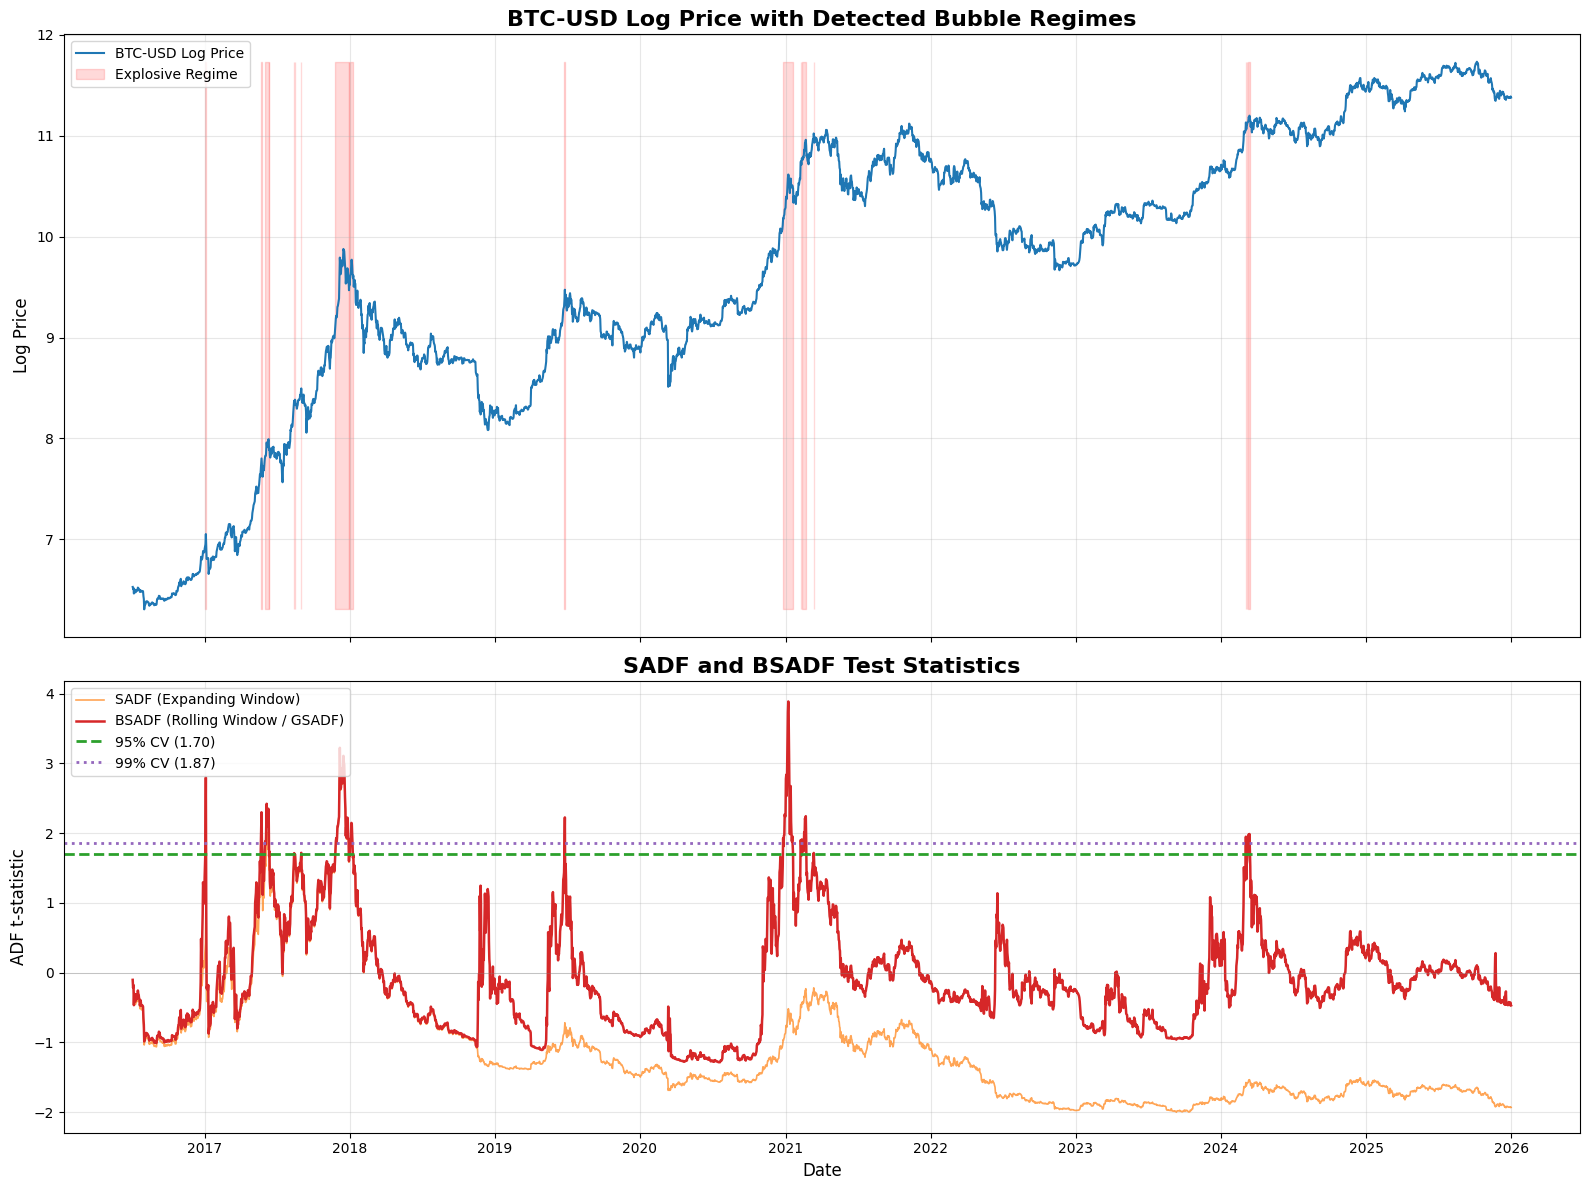

In [5]:
# Build unified DataFrame
df = pd.DataFrame({
    'BTC_Log_Price': btc_log,
    'SADF': btc_sadf,
    'BSADF': btc_bsadf
}).dropna()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 12), sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})

# --- Top Panel: BTC Log Price ---
ax1.plot(df.index, df['BTC_Log_Price'], color='#1f77b4', lw=1.5, label='BTC-USD Log Price')

# Highlight bubble regimes (where BSADF > 95% CV) using fill_between for smooth shading
bubble_mask = df['BSADF'] > cv_95
ax1.fill_between(df.index, df['BTC_Log_Price'].min(), df['BTC_Log_Price'].max(),
                 where=bubble_mask, color='red', alpha=0.15, label='Explosive Regime')
ax1.set_title('BTC-USD Log Price with Detected Bubble Regimes', fontsize=16, fontweight='bold')
ax1.set_ylabel('Log Price', fontsize=12)
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3)

# --- Bottom Panel: SADF & BSADF Statistics ---
ax2.plot(df.index, df['SADF'], color='#ff7f0e', lw=1.2, alpha=0.7, label='SADF (Expanding Window)')
ax2.plot(df.index, df['BSADF'], color='#d62728', lw=1.8, label='BSADF (Rolling Window / GSADF)')

ax2.axhline(y=cv_95, color='#2ca02c', linestyle='--', lw=2, label=f'95% CV ({cv_95:.2f})')
ax2.axhline(y=cv_99, color='#9467bd', linestyle=':', lw=2, label=f'99% CV ({cv_99:.2f})')
ax2.axhline(y=0, color='grey', linestyle='-', lw=0.5, alpha=0.5)

ax2.set_title('SADF and BSADF Test Statistics', fontsize=16, fontweight='bold')
ax2.set_ylabel('ADF t-statistic', fontsize=12)
ax2.set_xlabel('Date', fontsize=12)
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Phase 6.5: Look-Ahead Bias Audit

Before running any backtest, every stage of the data pipeline must be verified as strictly causal — each computation at time $t$ must use only information available up to and including $t$.

| Stage | Implementation Detail | Verdict |
|---|---|---|
| `ffill()` on raw prices | Propagates previous known close forward — causal by definition | ✅ **Clean** |
| `np.log()` | Element-wise transformation, no cross-time dependency | ✅ **Clean** |
| `calculate_sadf_sequence()` | Uses `dy[:t]` and `y_lag[:t]` — only data up to time $t$ | ✅ **Clean** |
| `calculate_bsadf_sequence()` | Sub-windows `[s:t]` always end at current time $t$ | ✅ **Clean** |
| `monte_carlo_sadf_cv()` | Simulates synthetic data; no dependency on real price data | ✅ **Clean** |
| Signal `shift(1)` | Signal at close of day $t$ → executed at close of day $t+1$ | ✅ **Clean** |

### Critical Note on Monte Carlo
The Monte Carlo critical values depend on $N$ (the sample length). If you add more data points in the future, you must re-run the simulation to get updated critical values.

## Phase 7: Quantitative Strategy — "Ride the Bubble"

### Strategy Logic
We formulate a simple **Trend Following** strategy that capitalizes on detected explosive regimes:

1. **Entry:** Go LONG when the BSADF statistic crosses **above** the 95% critical value. This signals that mean-reversion is structurally dead — momentum and euphoria have taken over.
2. **Exit:** Close the LONG position when the BSADF statistic drops **below** the 95% critical value. The explosive regime has fractured.
3. **Execution Delay:** All signals are shifted by 1 day (`shift(1)`) to prevent execution at the same price that triggered the signal.

---

### Performance Metric Formulas

#### Sharpe Ratio
$$\text{Sharpe} = \frac{\bar{r}}{\sigma_r} \cdot \sqrt{252}$$

#### Maximum Drawdown
$$\text{MDD} = \min_t \left( \frac{V_t - \max_{s \le t} V_s}{\max_{s \le t} V_s} \right)$$

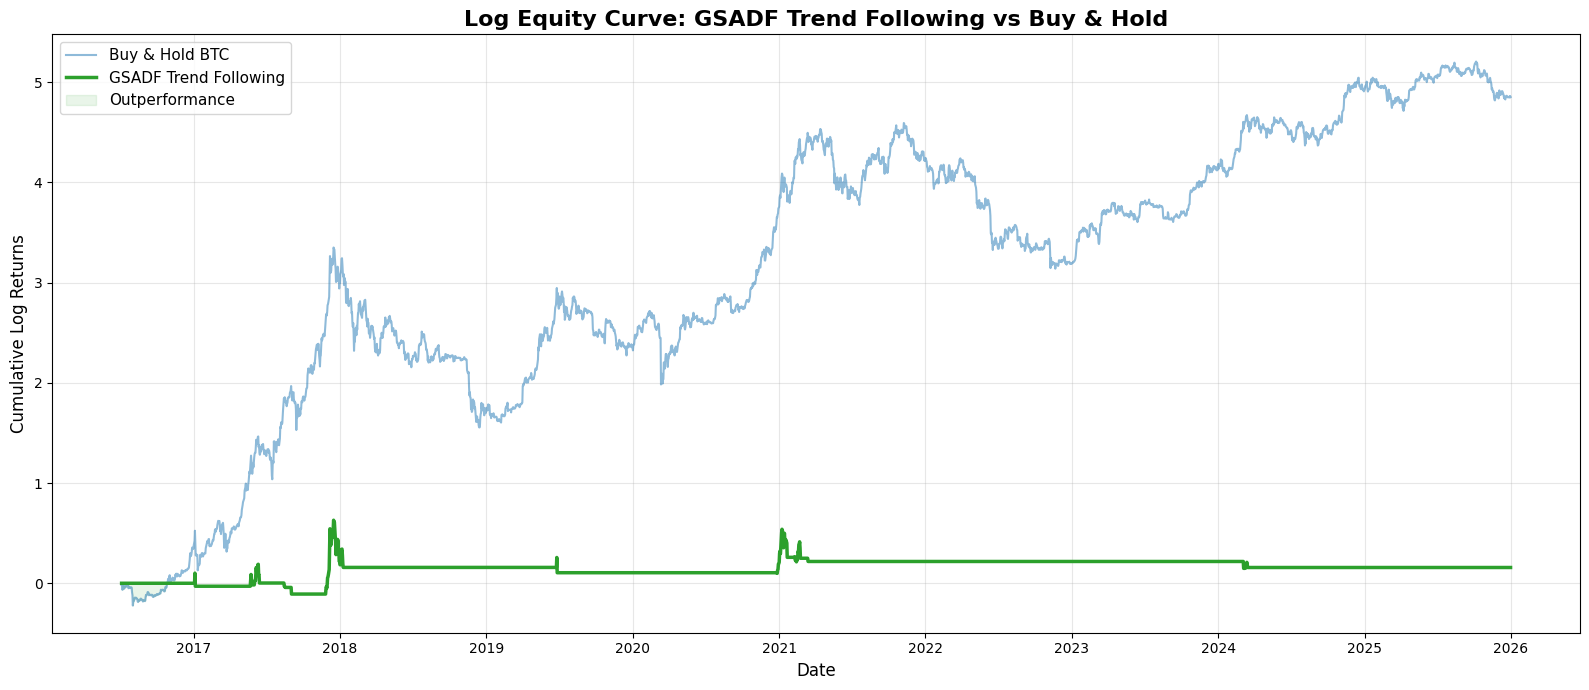

PERFORMANCE COMPARISON
Metric                          GSADF Strategy      Buy & Hold
------------------------------------------------------------
Annualized Sharpe Ratio                  0.062           0.624
Max Drawdown (log)                      -0.530          -1.796
Total Log Return                         0.157           4.852
Time in Market (%)                        3.3%          100.0%


In [6]:
# Build strategy
df['Returns'] = df['BTC_Log_Price'].diff()

# Signal: Long if BSADF > 95% CV, else Neutral (cash)
# SHIFT by 1 to prevent lookahead bias!
df['Signal'] = np.where(df['BSADF'] > cv_95, 1, 0)
df['Signal'] = df['Signal'].shift(1)

df['Strat_Returns'] = df['Signal'] * df['Returns']

# Cumulative log returns
df['Cum_Market'] = df['Returns'].cumsum()
df['Cum_Strat'] = df['Strat_Returns'].cumsum()

# --- Equity Curve ---
fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(df.index, df['Cum_Market'], label='Buy & Hold BTC', color='#1f77b4', alpha=0.5, lw=1.5)
ax.plot(df.index, df['Cum_Strat'], label='GSADF Trend Following', color='#2ca02c', lw=2.5)

ax.fill_between(df.index, df['Cum_Strat'], df['Cum_Market'],
                where=(df['Cum_Strat'] > df['Cum_Market']),
                color='#2ca02c', alpha=0.1, interpolate=True, label='Outperformance')

ax.set_title('Log Equity Curve: GSADF Trend Following vs Buy & Hold', fontsize=16, fontweight='bold')
ax.set_ylabel('Cumulative Log Returns', fontsize=12)
ax.set_xlabel('Date', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Performance Metrics ---
strat_daily = df['Strat_Returns'].dropna()
market_daily = df['Returns'].dropna()

sharpe_strat = (strat_daily.mean() / strat_daily.std()) * np.sqrt(252)
sharpe_market = (market_daily.mean() / market_daily.std()) * np.sqrt(252)

# Max Drawdown
cum_strat = strat_daily.cumsum()
rolling_max_s = cum_strat.cummax()
drawdown_s = cum_strat - rolling_max_s

cum_market = market_daily.cumsum()
rolling_max_m = cum_market.cummax()
drawdown_m = cum_market - rolling_max_m

print("=" * 60)
print("PERFORMANCE COMPARISON")
print("=" * 60)
print(f"{'Metric':<30} {'GSADF Strategy':>15} {'Buy & Hold':>15}")
print("-" * 60)
print(f"{'Annualized Sharpe Ratio':<30} {sharpe_strat:>15.3f} {sharpe_market:>15.3f}")
print(f"{'Max Drawdown (log)':<30} {drawdown_s.min():>15.3f} {drawdown_m.min():>15.3f}")
print(f"{'Total Log Return':<30} {cum_strat.iloc[-1]:>15.3f} {cum_market.iloc[-1]:>15.3f}")
print(f"{'Time in Market (%)':<30} {df['Signal'].mean() * 100:>14.1f}% {'100.0':>14}%")
print("=" * 60)

## Phase 8: Cross-Asset Verification — SPY

A robust bubble detection framework should behave differently across asset classes. SPY (S&P 500 ETF) is a diversified equity index that rarely exhibits sustained explosive behaviour. Let's run the SADF sequence on SPY and compare.

Calculating SADF sequence (min_window=182)...


SADF: 100%|██████████| 3468/3468 [00:00<00:00, 3677.63it/s]


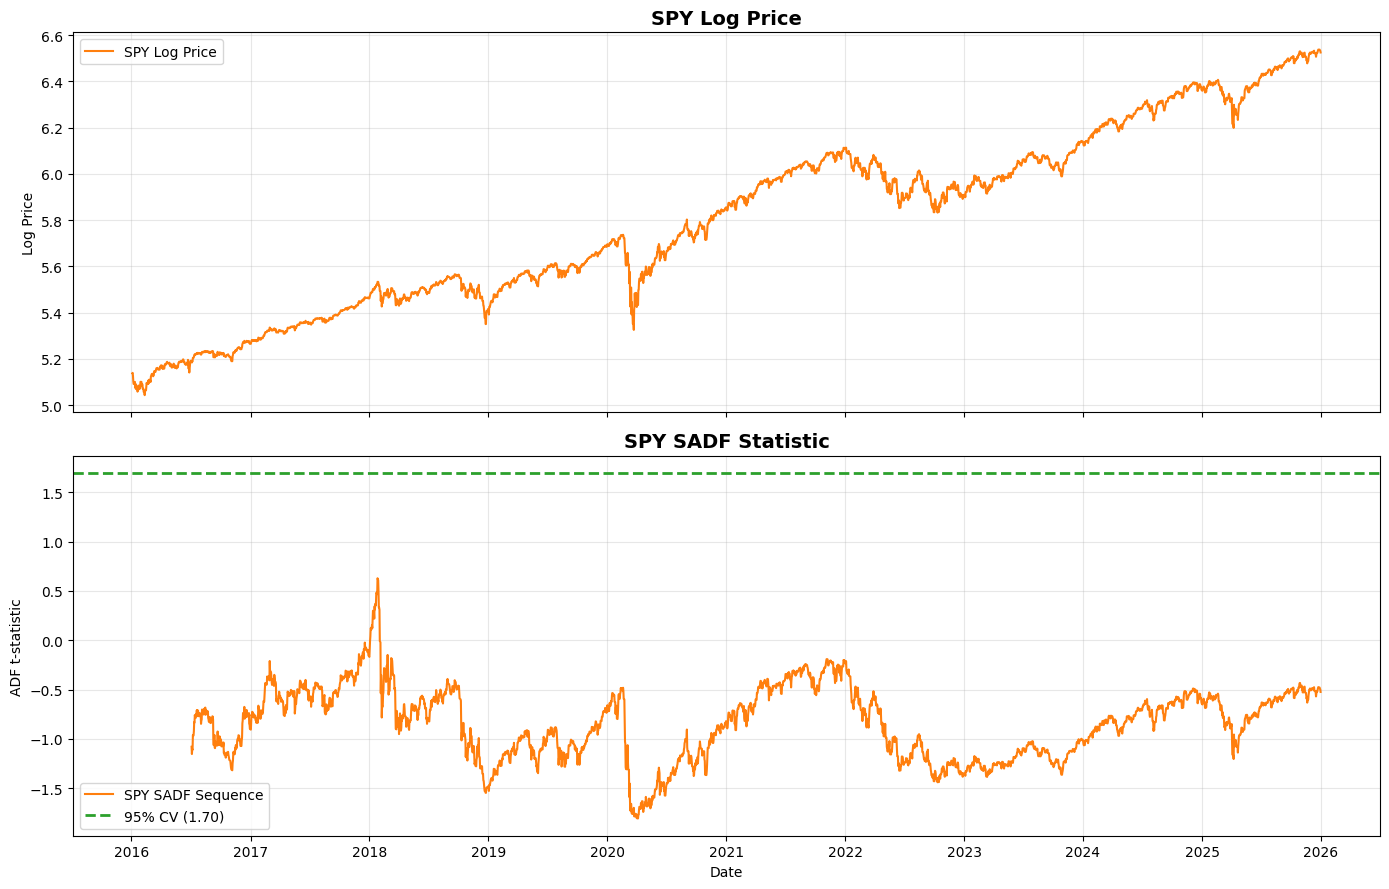

SPY Supremum SADF: 0.6292
BTC Supremum SADF: 3.2069

As expected, BTC shows dramatically higher explosive statistics than SPY.


In [7]:
# Calculate SADF for SPY
spy_sadf = calculate_sadf_sequence(spy_log, min_window=min_window_size)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

ax1.plot(spy_log.index, spy_log, color='#ff7f0e', lw=1.5, label='SPY Log Price')
ax1.set_title('SPY Log Price', fontsize=14, fontweight='bold')
ax1.set_ylabel('Log Price')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(spy_sadf.index, spy_sadf, color='#ff7f0e', lw=1.5, label='SPY SADF Sequence')
ax2.axhline(y=cv_95, color='#2ca02c', linestyle='--', lw=2, label=f'95% CV ({cv_95:.2f})')
ax2.set_title('SPY SADF Statistic', fontsize=14, fontweight='bold')
ax2.set_ylabel('ADF t-statistic')
ax2.set_xlabel('Date')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"SPY Supremum SADF: {np.nanmax(spy_sadf.values):.4f}")
print(f"BTC Supremum SADF: {np.nanmax(btc_sadf.values):.4f}")
print("\nAs expected, BTC shows dramatically higher explosive statistics than SPY.")

## Phase 9: Limitations and Practical Considerations

### 1. Computational Cost
GSADF/BSADF has $O(N^2)$ complexity per time step. For tick-level or minute-level data, this becomes impractical without C++/Numba optimization or pre-computed lookup tables.

### 2. Parameter Sensitivity
The choice of minimum window $r_0$ significantly affects detection sensitivity:
- **Too small:** False positives from noisy micro-regimes.
- **Too large:** Delayed detection — by the time the window is large enough, the bubble may already be collapsing.

### 3. Critical Value Dependency on $N$
Monte Carlo critical values depend on the sample size $N$. As you accumulate more data, critical values must be re-simulated.

### 4. Not a Standalone Strategy
SADF/GSADF detects structural regime changes. It should be combined with position sizing, risk management (stop-losses), and corroborating signals (volume, sentiment, on-chain metrics for crypto).

### 5. Overfitting Risk
The 95% threshold was derived from the same data. In production, you would use walk-forward analysis or out-of-sample testing to validate the threshold's robustness.

---

### Further Reading
- Phillips, P.C.B., Wu, Y., and Yu, J. (2011). "Explosive Behavior in the 1990s NASDAQ: When Did Exuberance Escalate Asset Values?"
- Phillips, P.C.B., Shi, S., and Yu, J. (2015). "Testing for Multiple Bubbles: Historical Episodes of Exuberance and Collapse in the S&P 500."
- López de Prado, M. (2018). "Advances in Financial Machine Learning," Chapter 17 — Structural Breaks.